In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

df = pd.read_csv("spotify_raw.csv")
print(f"Raw shape: {df.shape}")
df.head()

Raw shape: (114000, 20)


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [2]:
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])

df = df.dropna(subset=["artists", "album_name", "track_name"])

# Spotify occasionally has duplicate track_ids from re-releases / remasters - keep first occurrence
before = len(df)
df = df.drop_duplicates(subset=["track_id"])
print(f"\nDropped {before - len(df)} duplicate track_ids -> {len(df):,} tracks remain")

genres_held_out = df["track_genre"]   # kept aside only for the final sanity check, never used in clustering
print(f"Genres: {df['track_genre'].nunique()}, Artists: {df['artists'].nunique()}")

Missing values per column:
artists       1
album_name    1
track_name    1
dtype: int64

Dropped 24259 duplicate track_ids -> 89,740 tracks remain
Genres: 113, Artists: 31437


In [3]:
audio_features = ["danceability", "energy", "loudness", "speechiness",
                   "acousticness", "instrumentalness", "liveness", "valence",
                   "tempo", "duration_ms"]

X = df[audio_features].copy()
X.describe().round(3).T

,count,mean,std,min,25%,50%,75%,max
danceability,89740.0,0.562,0.177,0.000,0.450,0.576,0.692,0.985
energy,89740.0,0.634,0.257,0.000,0.457,0.676,0.853,1.000
loudness,89740.0,-8.499,5.222,-49.531,-10.322,-7.185,-5.108,4.532
speechiness,89740.0,0.087,0.113,0.000,0.036,0.049,0.086,0.965
acousticness,89740.0,0.328,0.338,0.000,0.017,0.188,0.625,0.996
instrumentalness,89740.0,0.173,0.324,0.000,0.000,0.000,0.098,1.000
liveness,89740.0,0.217,0.195,0.000,0.098,0.132,0.279,1.000
valence,89740.0,0.469,0.263,0.000,0.249,0.457,0.682,0.995
tempo,89740.0,122.058,30.118,0.000,99.263,122.013,140.077,243.372
duration_ms,89740.0,229144.366,112945.780,8586.000,173040.000,213295.500,264293.000,5237295.000


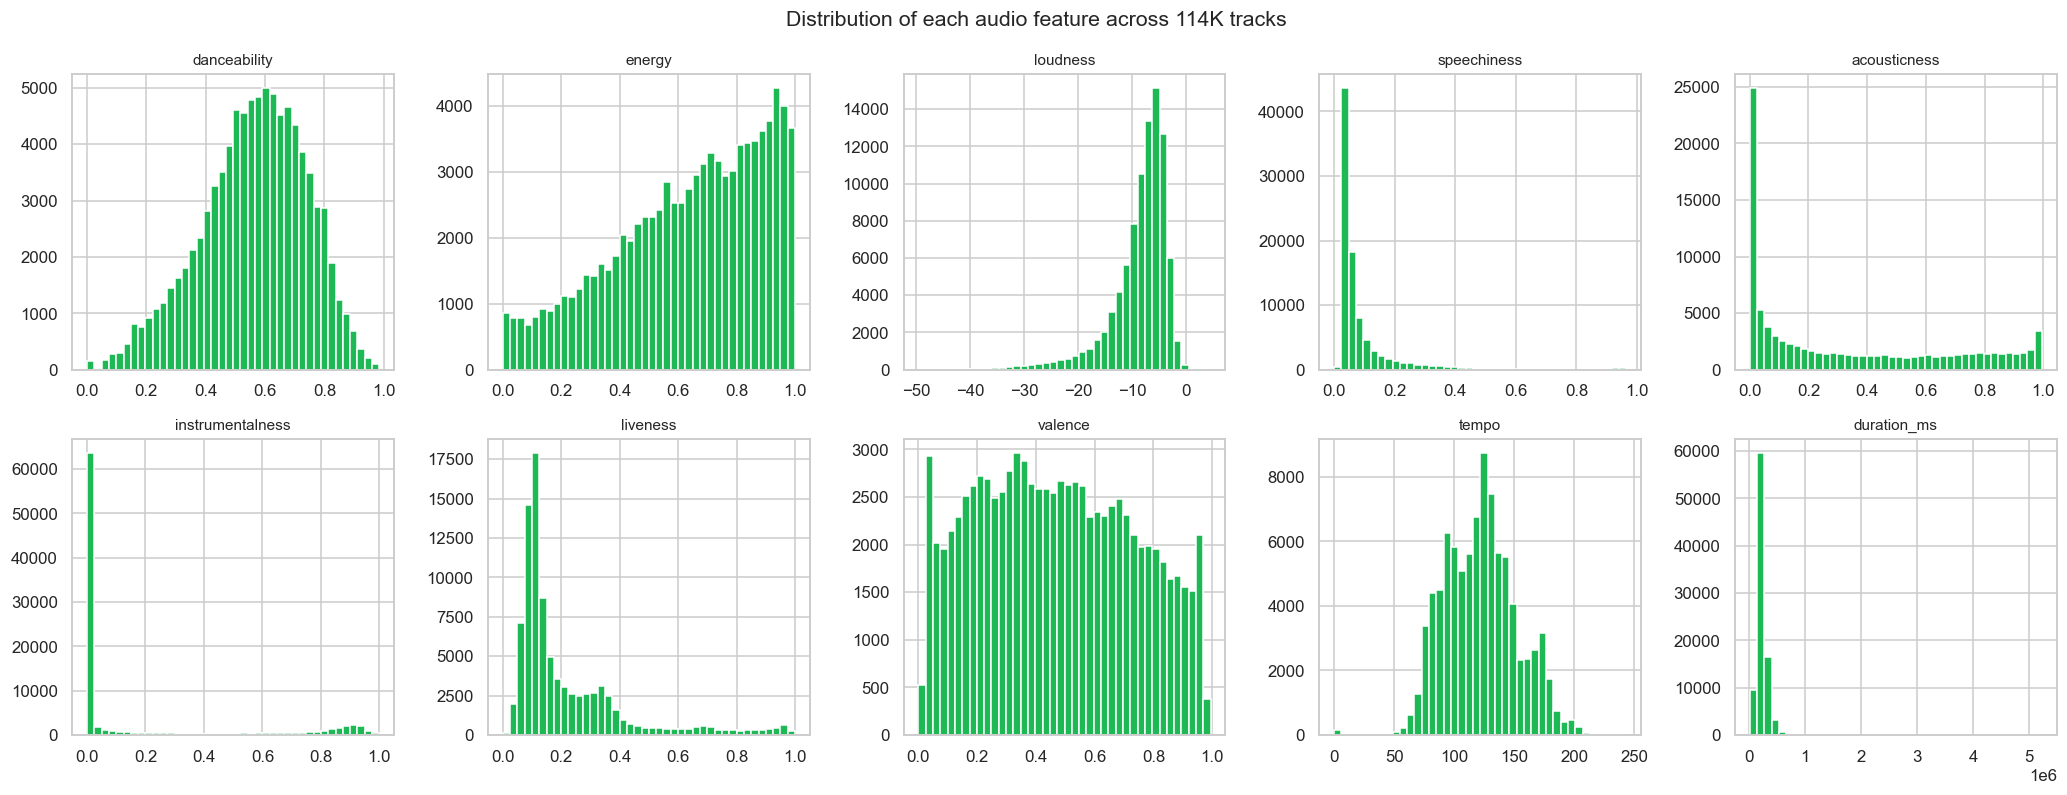

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(19, 7))
for ax, col in zip(axes.flat, audio_features):
    ax.hist(X[col], bins=40, color="#1DB954", edgecolor="white")
    ax.set_title(col, fontsize=10)
plt.tight_layout()
plt.suptitle("Distribution of each audio feature across 114K tracks", y=1.03, fontsize=14)
plt.savefig("hist_features.png", bbox_inches="tight")
plt.show()

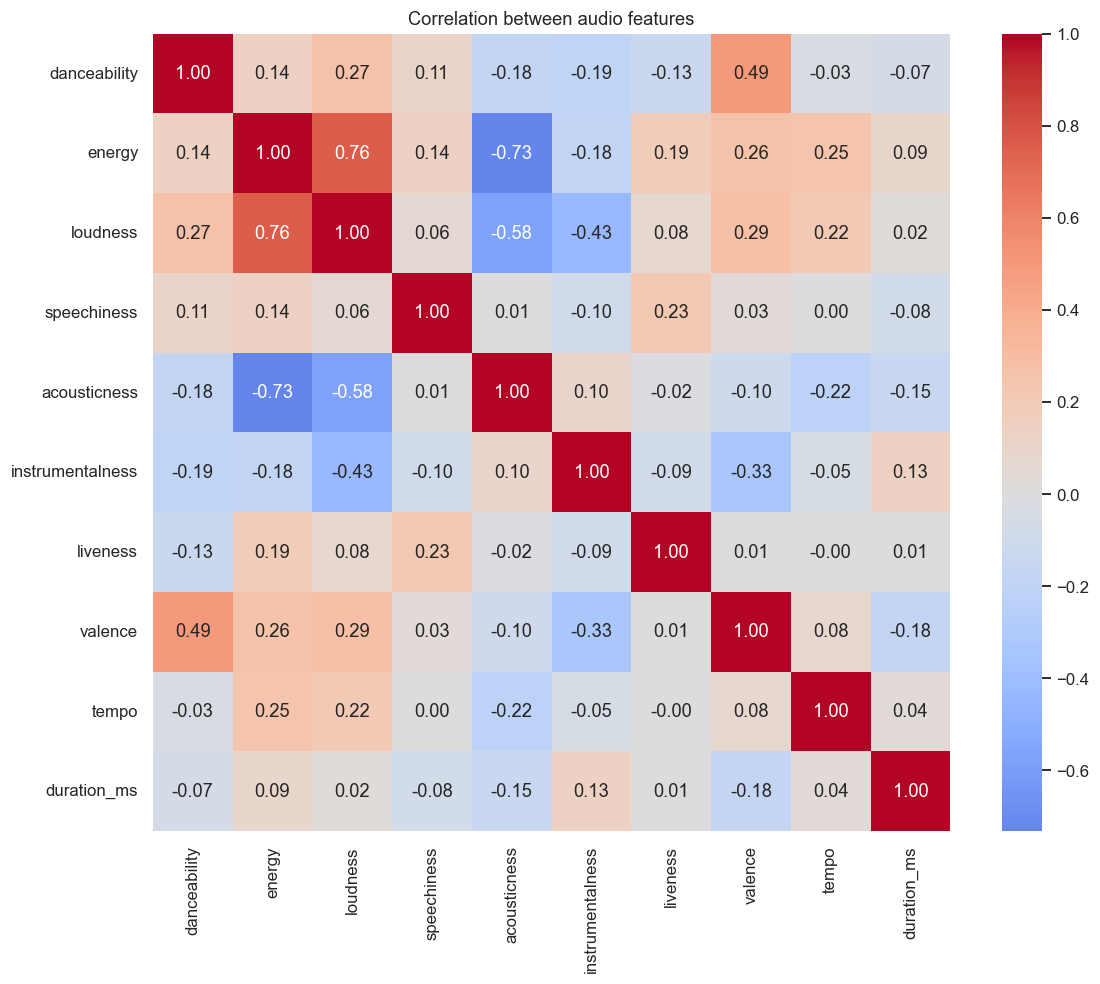

In [5]:
for col in ["duration_ms", "tempo"]:
    lo, hi = X[col].quantile([0.01, 0.99])
    X[col] = X[col].clip(lo, hi)

plt.figure(figsize=(11, 9))
sns.heatmap(X.corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f", square=True)
plt.title("Correlation between audio features")
plt.tight_layout()
plt.savefig("corr_heatmap.png", bbox_inches="tight")
plt.show()

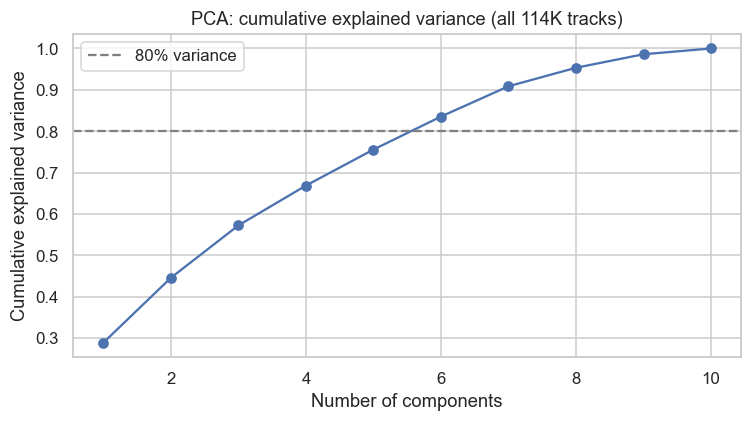

Variance explained by first 2 PCs: 44.54%


In [6]:
scaler = StandardScaler()
X_scaled_full = pd.DataFrame(scaler.fit_transform(X), columns=audio_features)

pca_full = PCA().fit(X_scaled_full)
explained = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(7,4))
plt.plot(range(1, len(explained)+1), explained, marker="o")
plt.axhline(0.8, color="grey", linestyle="--", label="80% variance")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA: cumulative explained variance (all 114K tracks)")
plt.legend()
plt.tight_layout()
plt.savefig("pca_variance.png", bbox_inches="tight")
plt.show()
print(f"Variance explained by first 2 PCs: {pca_full.explained_variance_ratio_[:2].sum():.2%}")

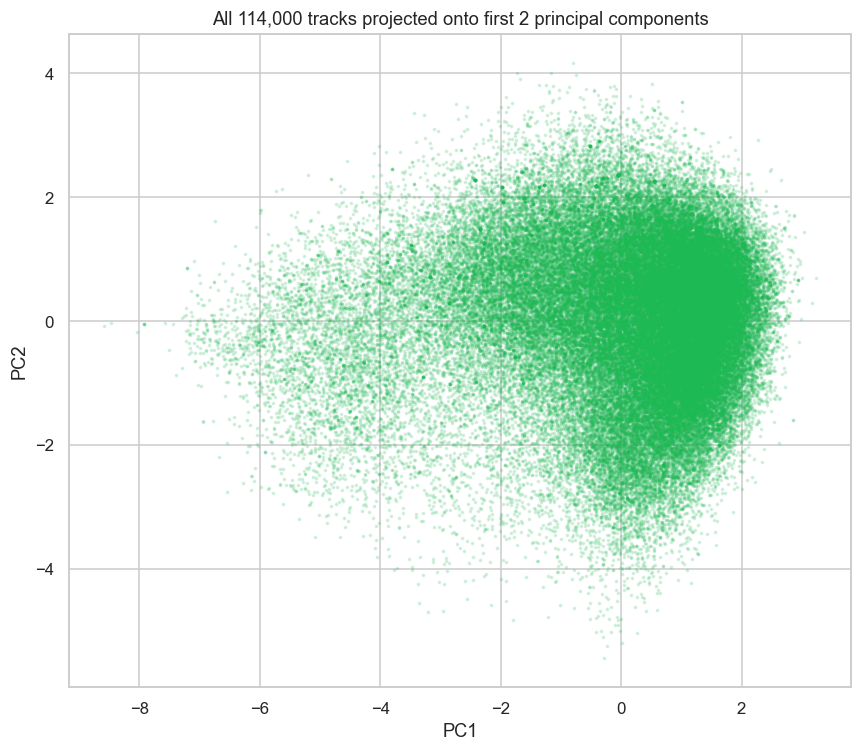

In [7]:
pca2 = PCA(n_components=2, random_state=42)
X_pca_full = pd.DataFrame(pca2.fit_transform(X_scaled_full), columns=["PC1", "PC2"])

plt.figure(figsize=(8,7))
plt.scatter(X_pca_full["PC1"], X_pca_full["PC2"], s=2, alpha=0.15, color="#1DB954")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("All 114,000 tracks projected onto first 2 principal components")
plt.tight_layout()
plt.savefig("pca_scatter_raw.png", bbox_inches="tight")
plt.show()

In [8]:
SAMPLE_N = 10000
sample_idx = X.sample(SAMPLE_N, random_state=42).index

X_sample = X.loc[sample_idx].reset_index(drop=True)
genres_sample = genres_held_out.loc[sample_idx].reset_index(drop=True)

X_scaled = pd.DataFrame(scaler.transform(X_sample), columns=audio_features)
X_pca = pd.DataFrame(pca2.transform(X_scaled), columns=["PC1", "PC2"])

print(f"Working sample: {len(X_sample):,} tracks")

Working sample: 10,000 tracks


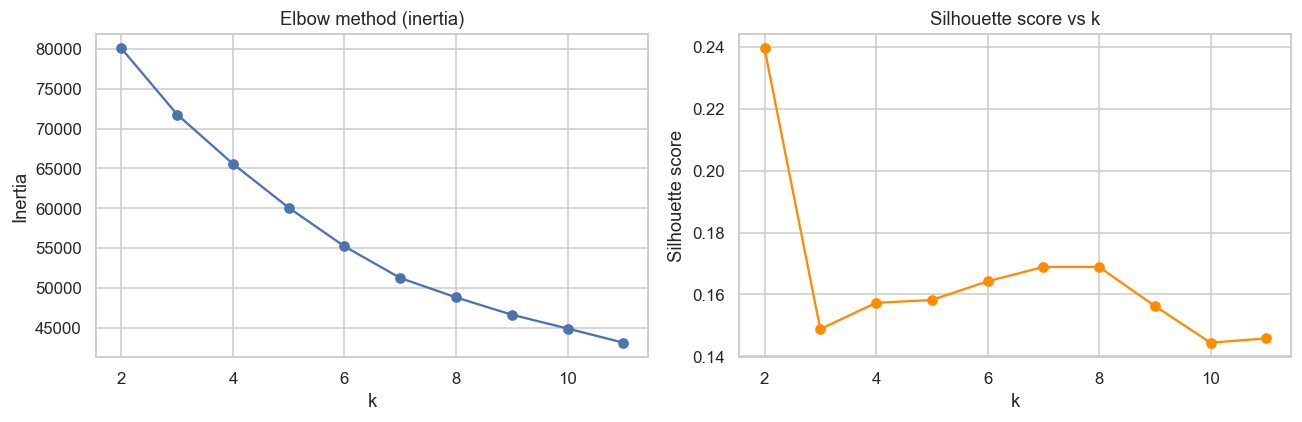

Best k by silhouette score: 2


In [9]:
inertias, sils = [], []
K_range = range(2, 12)
for k in K_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].plot(list(K_range), inertias, marker="o")
axes[0].set_title("Elbow method (inertia)")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")

axes[1].plot(list(K_range), sils, marker="o", color="darkorange")
axes[1].set_title("Silhouette score vs k")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette score")
plt.tight_layout()
plt.savefig("kmeans_k_selection.png", bbox_inches="tight")
plt.show()

best_k = list(K_range)[int(np.argmax(sils))]
print("Best k by silhouette score:", best_k)

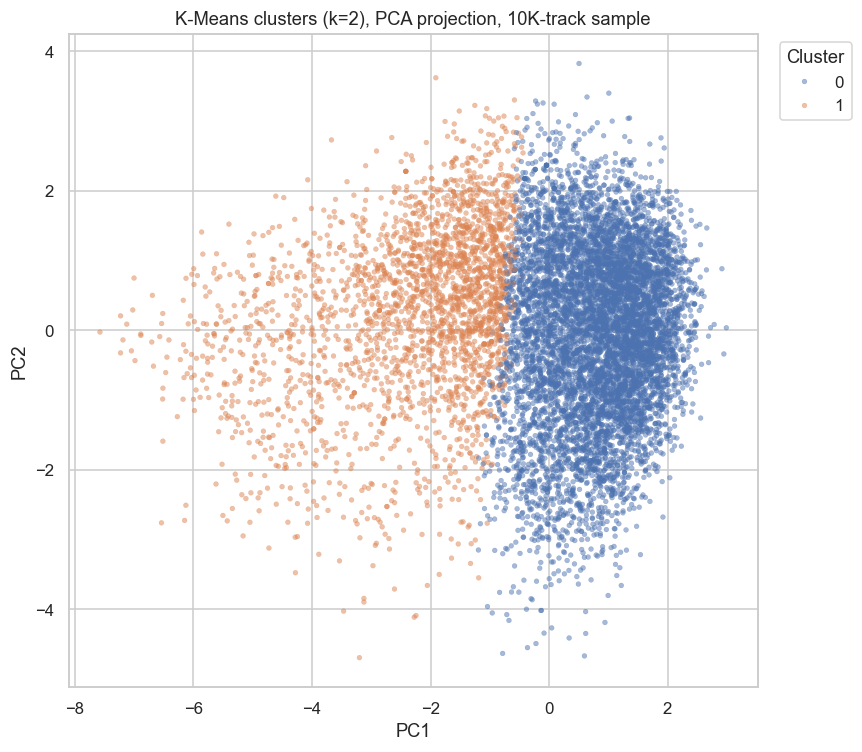

Silhouette: 0.239
Davies-Bouldin: 1.703


In [10]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)
km_labels = kmeans.fit_predict(X_scaled)

plt.figure(figsize=(8,7))
sns.scatterplot(x=X_pca["PC1"], y=X_pca["PC2"], hue=km_labels, palette="deep", s=10, alpha=0.5, edgecolor=None)
plt.title(f"K-Means clusters (k={best_k}), PCA projection, 10K-track sample")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("kmeans_pca.png", bbox_inches="tight")
plt.show()

print("Silhouette:", round(silhouette_score(X_scaled, km_labels), 3))
print("Davies-Bouldin:", round(davies_bouldin_score(X_scaled, km_labels), 3))

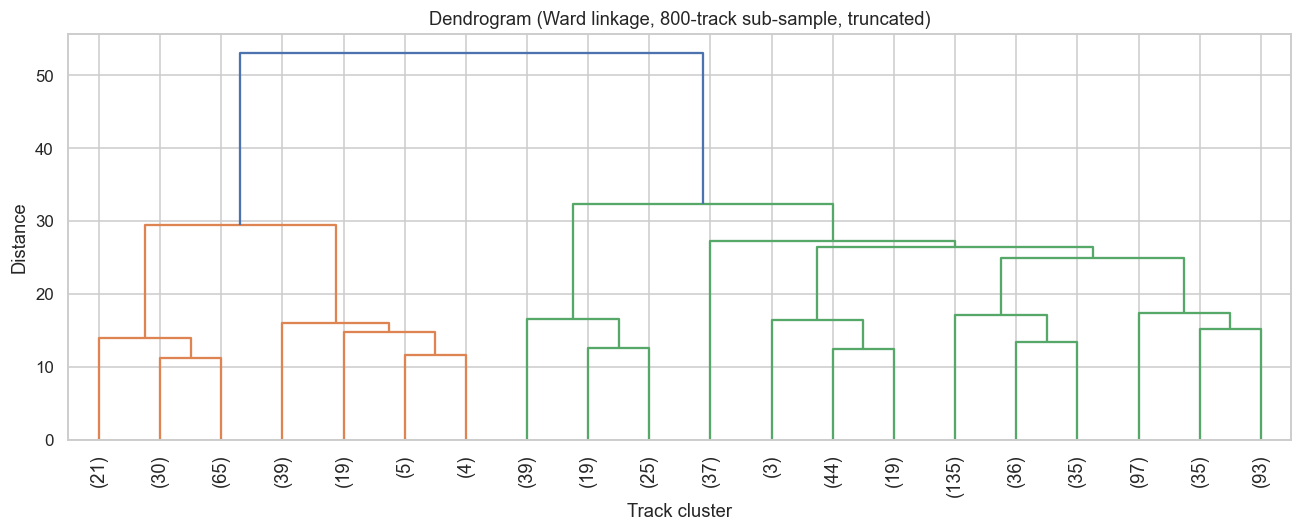

In [11]:
from scipy.cluster.hierarchy import dendrogram, linkage

dendro_idx = X_scaled.sample(800, random_state=1).index
Z = linkage(X_scaled.loc[dendro_idx], method="ward")

plt.figure(figsize=(12,5))
dendrogram(Z, truncate_mode="lastp", p=20, leaf_rotation=90)
plt.title("Dendrogram (Ward linkage, 800-track sub-sample, truncated)")
plt.xlabel("Track cluster")
plt.ylabel("Distance")
plt.tight_layout()
plt.savefig("dendrogram.png", bbox_inches="tight")
plt.show()

Best k for hierarchical (by silhouette): 3


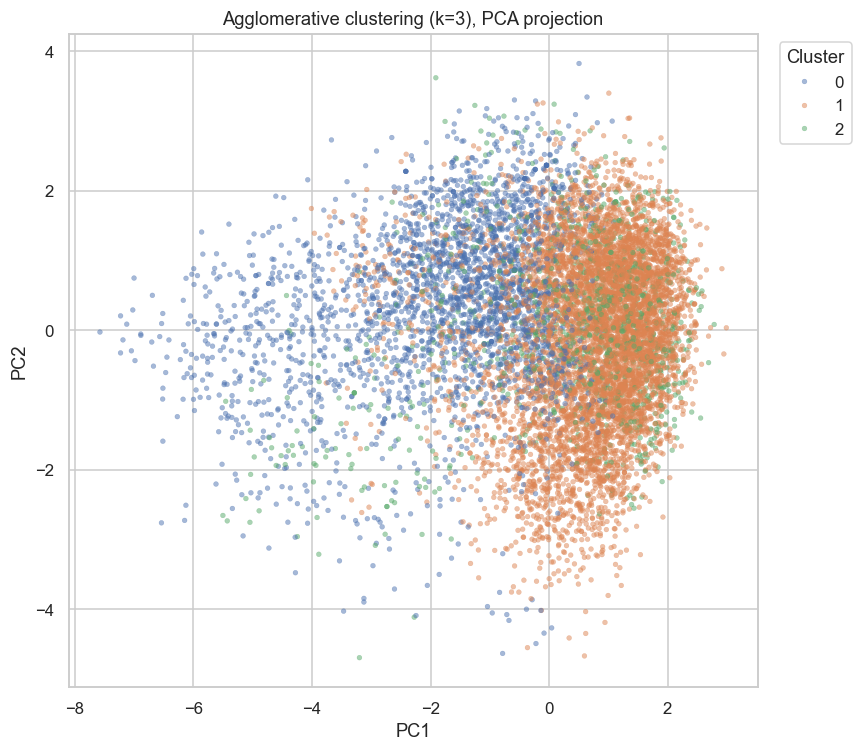

Silhouette: 0.156
Davies-Bouldin: 2.132


In [12]:
hier_sils = []
for k in K_range:
    hc = AgglomerativeClustering(n_clusters=k, linkage="ward")
    labels = hc.fit_predict(X_scaled)
    hier_sils.append(silhouette_score(X_scaled, labels))

best_k_hier = list(K_range)[int(np.argmax(hier_sils))]
print("Best k for hierarchical (by silhouette):", best_k_hier)

hier = AgglomerativeClustering(n_clusters=best_k_hier, linkage="ward")
hier_labels = hier.fit_predict(X_scaled)

plt.figure(figsize=(8,7))
sns.scatterplot(x=X_pca["PC1"], y=X_pca["PC2"], hue=hier_labels, palette="deep", s=10, alpha=0.5, edgecolor=None)
plt.title(f"Agglomerative clustering (k={best_k_hier}), PCA projection")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("hier_pca.png", bbox_inches="tight")
plt.show()

print("Silhouette:", round(silhouette_score(X_scaled, hier_labels), 3))
print("Davies-Bouldin:", round(davies_bouldin_score(X_scaled, hier_labels), 3))

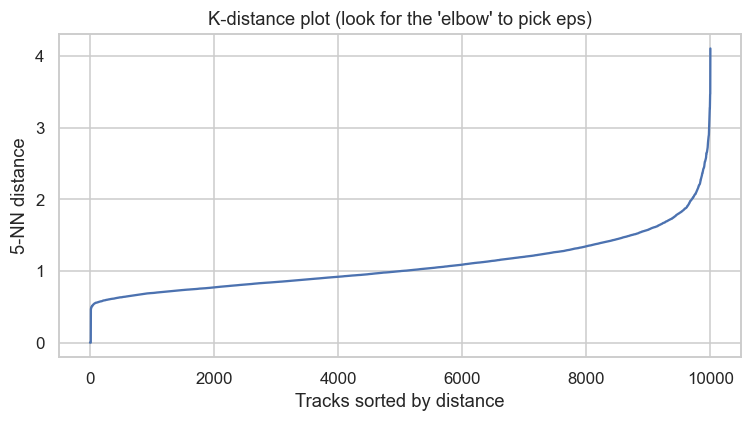

In [13]:
k_for_dbscan = 5
nbrs = NearestNeighbors(n_neighbors=k_for_dbscan).fit(X_scaled)
distances, _ = nbrs.kneighbors(X_scaled)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(7,4))
plt.plot(k_distances)
plt.xlabel("Tracks sorted by distance")
plt.ylabel(f"{k_for_dbscan}-NN distance")
plt.title("K-distance plot (look for the 'elbow' to pick eps)")
plt.tight_layout()
plt.savefig("dbscan_kdistance.png", bbox_inches="tight")
plt.show()

Best (eps, min_samples, n_clusters): (np.float64(0.4), 5, 2) | silhouette (non-noise points): 1.0
Clusters found: 2, noise points: 9987 / 10000 (99.9%)


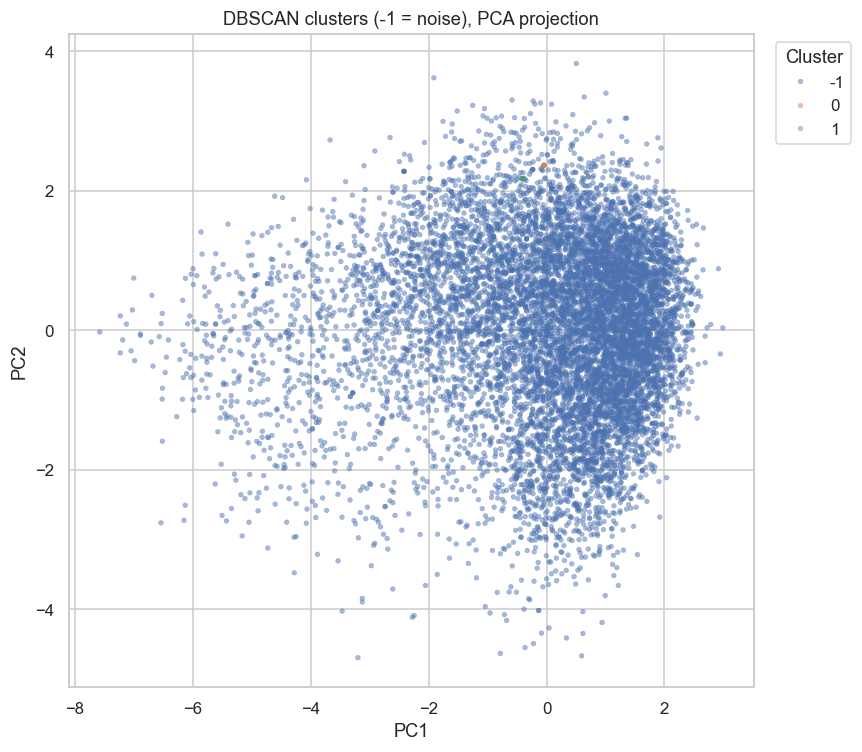

In [14]:
best_combo, best_score = None, -1
for eps in np.arange(0.4, 1.6, 0.1):
    for min_samples in [5, 10, 15, 20]:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        if n_clusters >= 2:
            mask = labels != -1
            if mask.sum() > 1 and len(set(labels[mask])) >= 2:
                score = silhouette_score(X_scaled[mask], labels[mask])
                if score > best_score:
                    best_score, best_combo = score, (eps, min_samples, n_clusters)

print("Best (eps, min_samples, n_clusters):", best_combo, "| silhouette (non-noise points):", round(best_score,3))

eps_best, min_samples_best, _ = best_combo
db = DBSCAN(eps=eps_best, min_samples=min_samples_best)
db_labels = db.fit_predict(X_scaled)

noise_fraction = (db_labels == -1).mean()
n_db_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
print(f"Clusters found: {n_db_clusters}, noise points: {(db_labels==-1).sum()} / {len(db_labels)} ({noise_fraction:.1%})")

plt.figure(figsize=(8,7))
sns.scatterplot(x=X_pca["PC1"], y=X_pca["PC2"], hue=db_labels, palette="deep", s=10, alpha=0.5, edgecolor=None)
plt.title("DBSCAN clusters (-1 = noise), PCA projection")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("dbscan_pca.png", bbox_inches="tight")
plt.show()

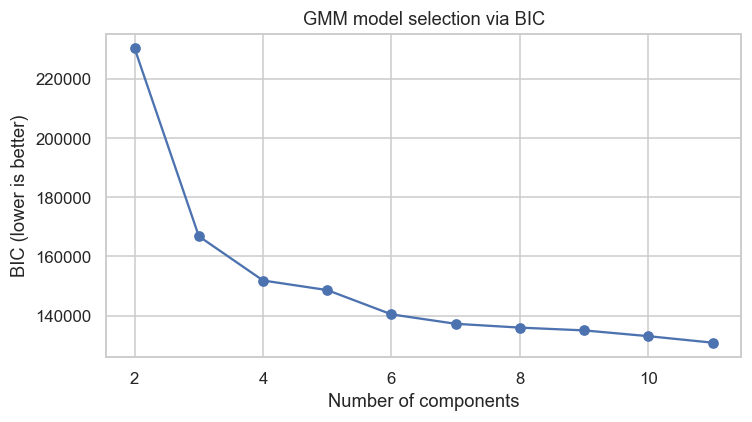

Best k for GMM (by BIC): 11


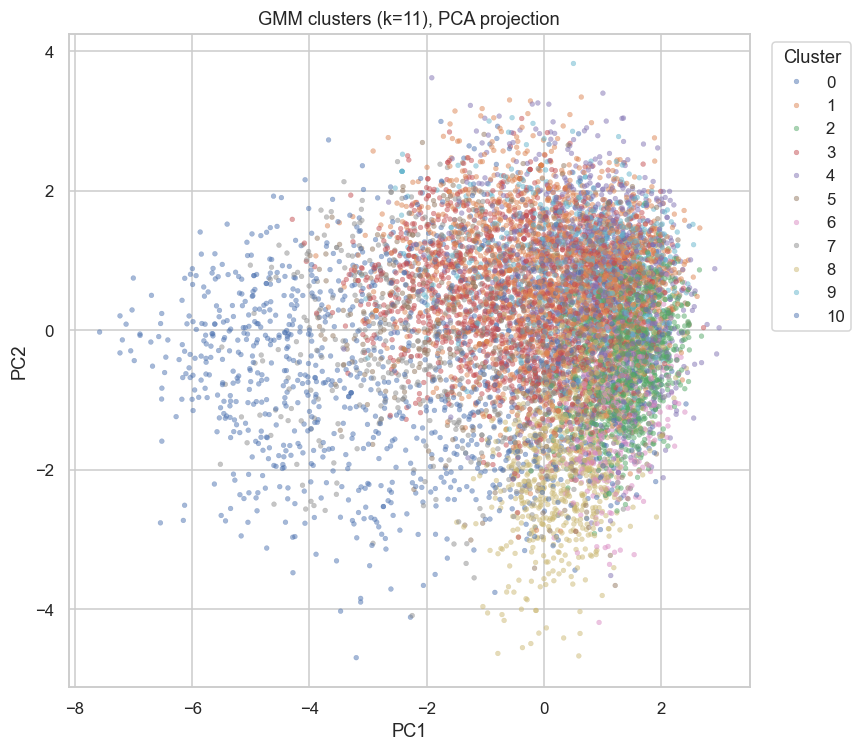

Silhouette: -0.037
Davies-Bouldin: 3.993


In [15]:
bics = []
for k in K_range:
    gmm = GaussianMixture(n_components=k, random_state=42, n_init=3).fit(X_scaled)
    bics.append(gmm.bic(X_scaled))

plt.figure(figsize=(7,4))
plt.plot(list(K_range), bics, marker="o")
plt.xlabel("Number of components")
plt.ylabel("BIC (lower is better)")
plt.title("GMM model selection via BIC")
plt.tight_layout()
plt.savefig("gmm_bic.png", bbox_inches="tight")
plt.show()

best_k_gmm = list(K_range)[int(np.argmin(bics))]
print("Best k for GMM (by BIC):", best_k_gmm)

gmm = GaussianMixture(n_components=best_k_gmm, random_state=42, n_init=3)
gmm_labels = gmm.fit_predict(X_scaled)

plt.figure(figsize=(8,7))
sns.scatterplot(x=X_pca["PC1"], y=X_pca["PC2"], hue=gmm_labels, palette="deep", s=10, alpha=0.5, edgecolor=None)
plt.title(f"GMM clusters (k={best_k_gmm}), PCA projection")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("gmm_pca.png", bbox_inches="tight")
plt.show()

print("Silhouette:", round(silhouette_score(X_scaled, gmm_labels), 3))
print("Davies-Bouldin:", round(davies_bouldin_score(X_scaled, gmm_labels), 3))

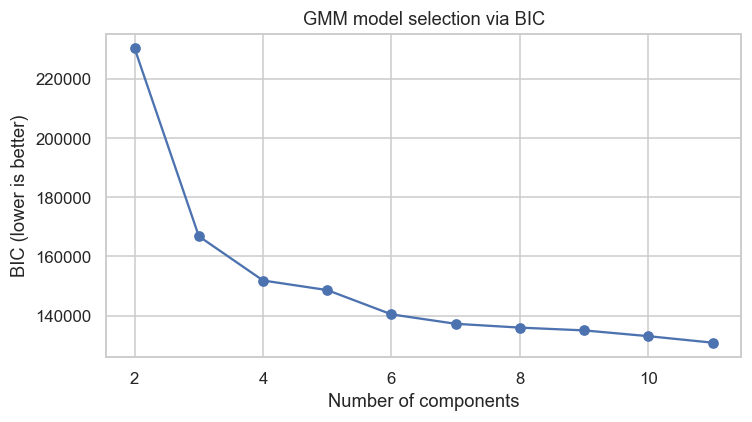

Best k for GMM (by BIC): 11


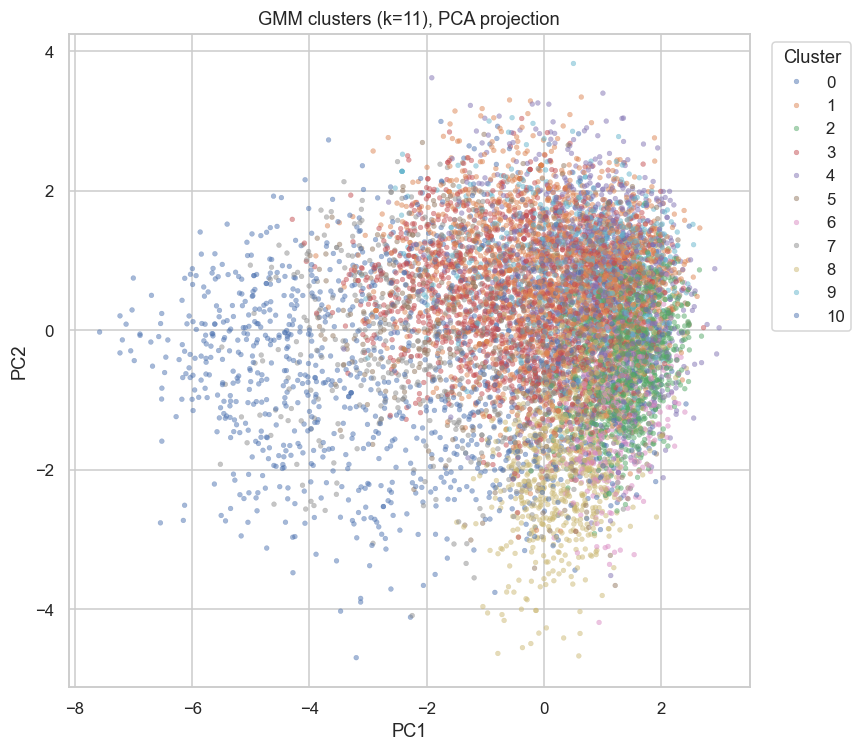

Silhouette: -0.037
Davies-Bouldin: 3.993


In [16]:
bics = []
for k in K_range:
    gmm = GaussianMixture(n_components=k, random_state=42, n_init=3).fit(X_scaled)
    bics.append(gmm.bic(X_scaled))

plt.figure(figsize=(7,4))
plt.plot(list(K_range), bics, marker="o")
plt.xlabel("Number of components")
plt.ylabel("BIC (lower is better)")
plt.title("GMM model selection via BIC")
plt.tight_layout()
plt.savefig("gmm_bic.png", bbox_inches="tight")
plt.show()

best_k_gmm = list(K_range)[int(np.argmin(bics))]
print("Best k for GMM (by BIC):", best_k_gmm)

gmm = GaussianMixture(n_components=best_k_gmm, random_state=42, n_init=3)
gmm_labels = gmm.fit_predict(X_scaled)

plt.figure(figsize=(8,7))
sns.scatterplot(x=X_pca["PC1"], y=X_pca["PC2"], hue=gmm_labels, palette="deep", s=10, alpha=0.5, edgecolor=None)
plt.title(f"GMM clusters (k={best_k_gmm}), PCA projection")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("gmm_pca.png", bbox_inches="tight")
plt.show()

print("Silhouette:", round(silhouette_score(X_scaled, gmm_labels), 3))
print("Davies-Bouldin:", round(davies_bouldin_score(X_scaled, gmm_labels), 3))

In [17]:
def safe_metric(labels, metric_fn):
    labels = np.array(labels)
    mask = labels != -1 if -1 in set(labels) else np.ones(len(labels), dtype=bool)
    if len(set(labels[mask])) < 2:
        return np.nan
    return metric_fn(X_scaled[mask], labels[mask])

def largest_cluster_share(labels):
    labels = np.array(labels)
    labels = labels[labels != -1]
    return pd.Series(labels).value_counts(normalize=True).max()

results = pd.DataFrame({
    "Model": ["K-Means", "Agglomerative", "DBSCAN", "GMM"],
    "n_clusters_found": [best_k, best_k_hier, n_db_clusters, best_k_gmm],
    "noise_fraction": [0, 0, round(noise_fraction, 3), 0],
    "largest_cluster_share": [
        largest_cluster_share(km_labels), largest_cluster_share(hier_labels),
        largest_cluster_share(db_labels), largest_cluster_share(gmm_labels)
    ],
    "Silhouette": [
        safe_metric(km_labels, silhouette_score), safe_metric(hier_labels, silhouette_score),
        safe_metric(db_labels, silhouette_score), safe_metric(gmm_labels, silhouette_score)
    ],
    "Davies-Bouldin": [
        safe_metric(km_labels, davies_bouldin_score), safe_metric(hier_labels, davies_bouldin_score),
        safe_metric(db_labels, davies_bouldin_score), safe_metric(gmm_labels, davies_bouldin_score)
    ],
    "ARI_vs_genre (sanity check only)": [
        adjusted_rand_score(genres_sample, km_labels), adjusted_rand_score(genres_sample, hier_labels),
        adjusted_rand_score(genres_sample, db_labels), adjusted_rand_score(genres_sample, gmm_labels)
    ],
})
results.round(3)

,Model,n_clusters_found,noise_fraction,largest_cluster_share,Silhouette,Davies-Bouldin,ARI_vs_genre (sanity check only)
0,K-Means,2,0.000,0.747,0.239,1.703,0.005
1,Agglomerative,3,0.000,0.626,0.156,2.132,0.006
2,DBSCAN,2,0.999,0.615,1.000,0.000,0.000
3,GMM,11,0.000,0.187,-0.037,3.993,0.020


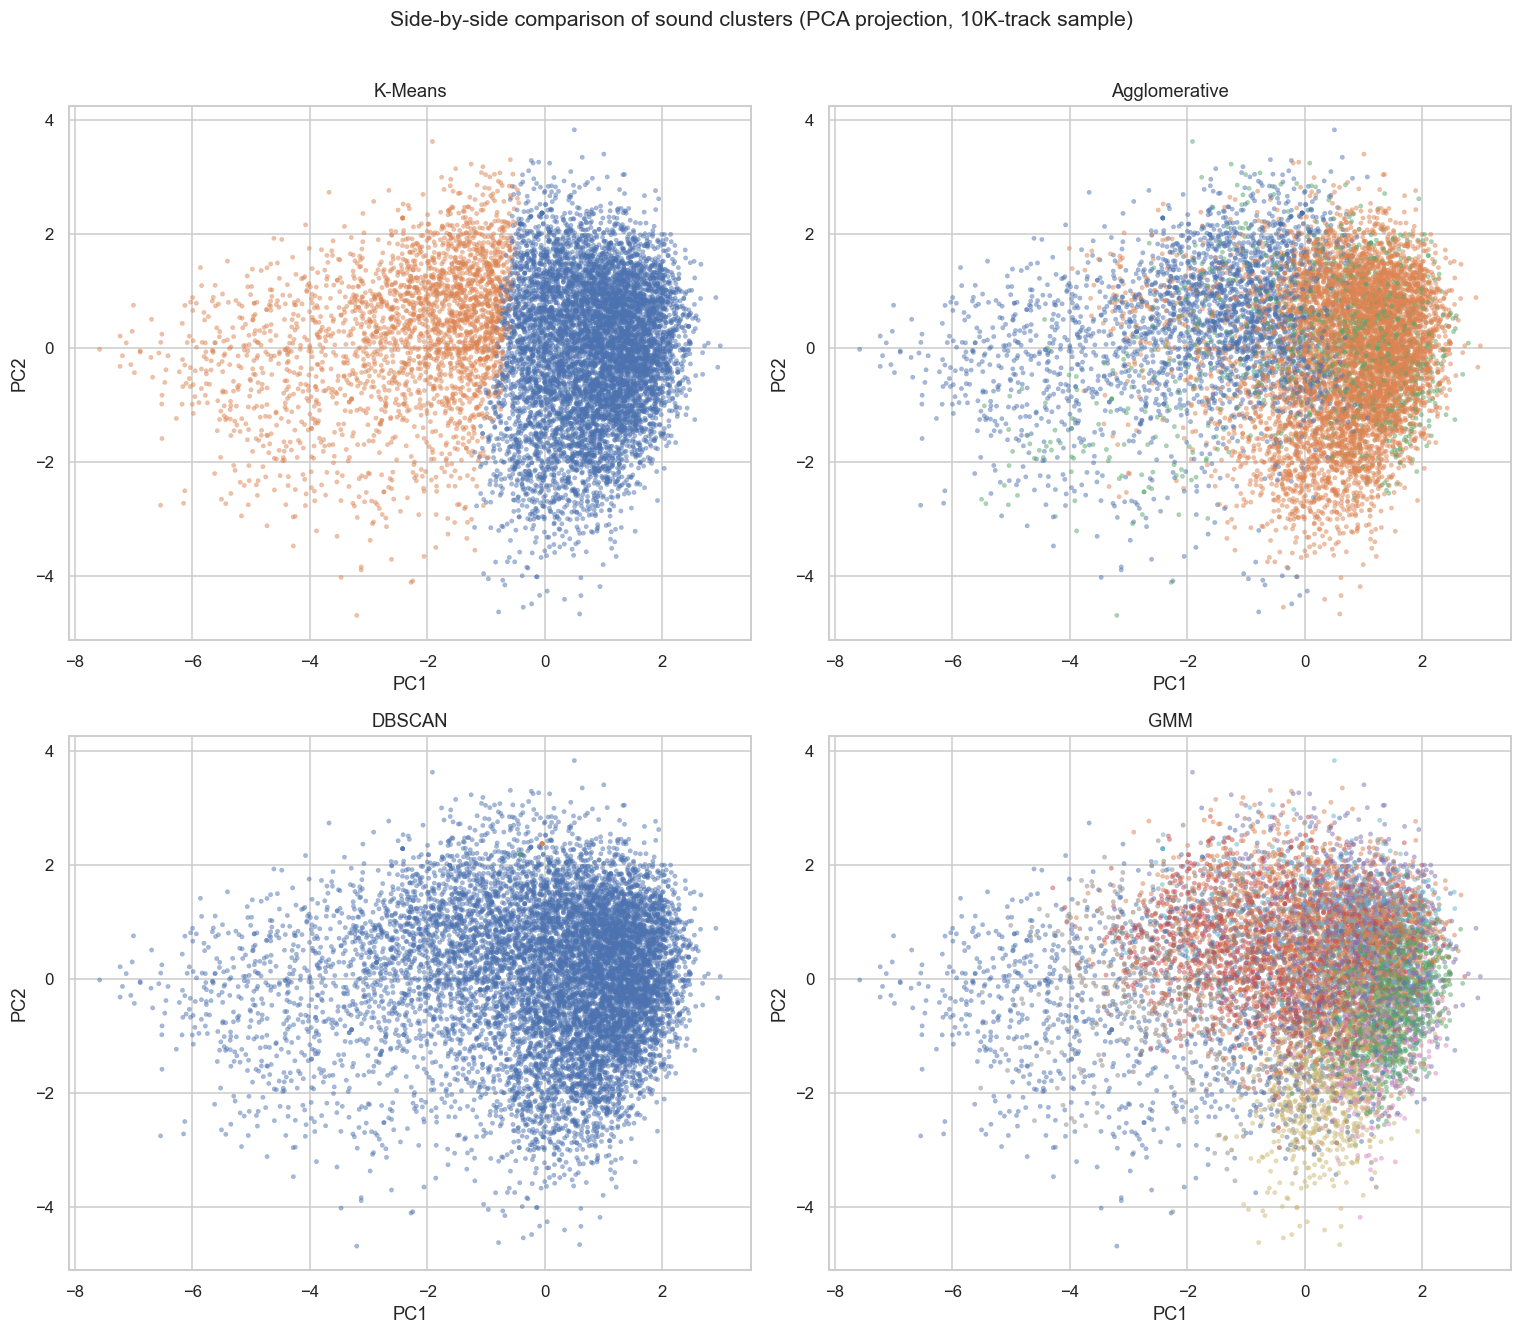

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(14,12))
titles = ["K-Means", "Agglomerative", "DBSCAN", "GMM"]
label_sets = [km_labels, hier_labels, db_labels, gmm_labels]

for ax, title, labels in zip(axes.flat, titles, label_sets):
    sns.scatterplot(x=X_pca["PC1"], y=X_pca["PC2"], hue=labels, palette="deep",
                     s=8, alpha=0.5, edgecolor=None, ax=ax, legend=False)
    ax.set_title(title)
plt.suptitle("Side-by-side comparison of sound clusters (PCA projection, 10K-track sample)", y=1.01, fontsize=14)
plt.tight_layout()
plt.savefig("all_models_comparison.png", bbox_inches="tight")
plt.show()

In [19]:
# Pick the best USABLE model: full coverage (not mostly "noise"), and not degenerate
# (no single cluster swallowing almost everything).
USABLE_MODELS = [name for name, labels in
                  zip(["K-Means", "Agglomerative", "DBSCAN", "GMM"],
                      [km_labels, hier_labels, db_labels, gmm_labels])
                  if (np.array(labels) == -1).mean() < 0.10
                  and largest_cluster_share(labels) < 0.85]

eligible = results[results["Model"].isin(USABLE_MODELS)]
best_model_name = eligible.loc[eligible["Silhouette"].idxmax(), "Model"]
print("Excluded (too much noise, or one cluster dominates):",
      [m for m in results["Model"] if m not in USABLE_MODELS])
print("Best usable model:", best_model_name)

Excluded (too much noise, or one cluster dominates): ['DBSCAN']
Best usable model: K-Means


In [20]:
label_map = {"K-Means": km_labels, "Agglomerative": hier_labels, "DBSCAN": db_labels, "GMM": gmm_labels}
best_labels = label_map[best_model_name]

profile = X_sample.copy()
profile["cluster"] = best_labels
profile = profile[profile["cluster"] != -1]

cluster_profile = profile.groupby("cluster")[audio_features].mean().round(3)
cluster_profile["n_tracks"] = profile.groupby("cluster").size()
cluster_profile["%_of_sample"] = (cluster_profile["n_tracks"] / len(profile) * 100).round(1)
cluster_profile.sort_values("energy", ascending=False)

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,n_tracks,%_of_sample
cluster,,,,,,,,,,,,
0,0.60,0.747,-6.529,0.098,0.184,0.120,0.224,0.530,126.306,230019.154,7467,74.7
1,0.46,0.305,-14.299,0.058,0.747,0.318,0.187,0.317,109.439,216687.536,2533,25.3


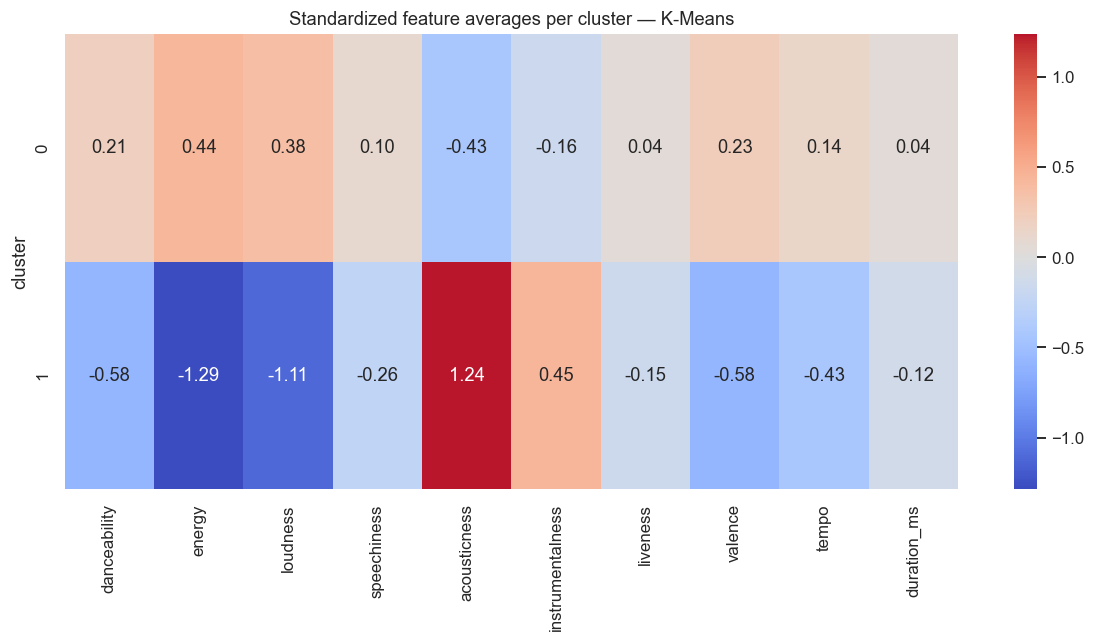

In [21]:
plt.figure(figsize=(11,6))
X_scaled_profile = X_scaled.copy()
X_scaled_profile["cluster"] = best_labels
X_scaled_profile = X_scaled_profile[X_scaled_profile["cluster"] != -1]
sns.heatmap(X_scaled_profile.groupby("cluster")[audio_features].mean(), annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title(f"Standardized feature averages per cluster — {best_model_name}")
plt.tight_layout()
plt.savefig("cluster_profile_heatmap.png", bbox_inches="tight")
plt.show()

In [22]:
# What genres actually dominate each cluster? (post-hoc check only, never used for training)
genre_check = pd.DataFrame({"cluster": best_labels, "genre": genres_sample})
genre_check = genre_check[genre_check["cluster"] != -1]

top_genres_per_cluster = (genre_check.groupby("cluster")["genre"]
                           .apply(lambda s: s.value_counts().head(3).index.tolist()))
for c, genres in top_genres_per_cluster.items():
    n = (genre_check["cluster"] == c).sum()
    print(f"Cluster {c} ({n} tracks) — top genres: {genres}")

Cluster 0 (7467 tracks) — top genres: ['chicago-house', 'heavy-metal', 'forro']
Cluster 1 (2533 tracks) — top genres: ['sleep', 'opera', 'new-age']
